In [ ]:
#importa a biblioteca
import pandas as pd
#define o caminho do arqv csv
caminho_arquivo = "/content/drive/MyDrive/generatedBy_react-csv (1).csv"
#ler o arqv e armazena os dados no dataframe "dados"
dados = pd.read_csv(caminho_arquivo, delimiter=";")
#imprimir
display(dados)

,Data,Hora (UTC),Temp. Ins. (C),Temp. Max. (C),Temp. Min. (C),Umi. Ins. (%),Umi. Max. (%),Umi. Min. (%),Pto Orvalho Ins. (C),Pto Orvalho Max. (C),Pto Orvalho Min. (C),Pressao Ins. (hPa),Pressao Max. (hPa),Pressao Min. (hPa),Vel. Vento (m/s),Dir. Vento (m/s),Raj. Vento (m/s),Radiacao (KJ/m²),Chuva (mm)
0,01/01/2023,0,"26,4","27,0","26,3","86,0","86,0","80,0","23,7","23,7","23,2","1002,6","1002,6","1001,2","0,2","14,0","2,2",NaN,"0,0"
1,01/01/2023,100,"25,8","26,4","25,8","89,0","89,0","86,0","23,8","23,9","23,6","1003,4","1003,4","1002,6","0,7","8,0","1,8",NaN,"0,0"
2,01/01/2023,200,"25,4","25,8","25,4","90,0","90,0","89,0","23,6","23,8","23,6","1004,2","1004,2","1003,4","0,1","45,0","1,8",NaN,"0,0"
3,01/01/2023,300,"25,3","25,5","25,3","91,0","91,0","90,0","23,7","23,8","23,6","1004,8","1004,9","1004,2","0,2","11,0","1,2",NaN,"0,0"
4,01/01/2023,400,"25,1","25,3","25,0","91,0","91,0","91,0","23,6","23,7","23,5","1004,2","1004,8","1004,2","0,2","352,0","1,4",NaN,"0,0"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,31/12/2023,1900,"29,7","31,9","29,7","66,0","69,0","56,0","22,8","24,0","21,7","1001,7","1003,6","1001,7","2,4","245,0","5,1","1010,50","0,0"
8756,31/12/2023,2000,"31,5","31,5","29,3","60,0","70,0","60,0","22,8","23,8","22,6","1000,7","1001,7","1000,7","0,5","253,0","4,3","1640,90","0,0"
8757,31/12/2023,2100,"30,5","31,5","29,7","65,0","69,0","60,0","23,3","24,3","22,4","1000,7","1000,7","1000,3","1,5","251,0","3,8","1484,00","0,0"
8758,31/12/2023,2200,"28,4","30,5","28,4","77,0","78,0","65,0","24,1","24,1","23,3","1001,4","1001,4","1000,5","1,4","219,0","3,5","300,10","0,0"


In [ ]:
import pandas as pd

# Carregar os dados do arquivo CSV
df = pd.read_csv('/content/drive/MyDrive/generatedBy_react-csv (1).csv', sep=';', encoding='utf-8', low_memory=False)

# Exibir os primeiros dados para checagem
print("\nDados brutos:")
print(df.head())

# Converter a coluna de data corretamente
df["Data"] = pd.to_datetime(df["Data"], dayfirst=True, errors='coerce')

# Lista de colunas numéricas
colunas_numericas = [
    "Temp. Ins. (C)", "Temp. Max. (C)", "Temp. Min. (C)", "Umi. Ins. (%)", "Umi. Max. (%)", "Umi. Min. (%)",
    "Pto Orvalho Ins. (C)", "Pto Orvalho Max. (C)", "Pto Orvalho Min. (C)", "Pressao Ins. (hPa)",
    "Pressao Max. (hPa)", "Pressao Min. (hPa)", "Vel. Vento (m/s)", "Dir. Vento (m/s)", "Raj. Vento (m/s)",
    "Radiacao (KJ/m²)", "Chuva (mm)"
]

# Converter colunas para numérico corretamente, trocando ',' por '.'
for col in colunas_numericas:
    df[col] = df[col].astype(str).str.replace(',', '.')
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Verificar tipos de dados
print("\nTipos de dados no DataFrame:")
print(df.dtypes)

# Estatísticas descritivas
print("\nEstatísticas básicas:")
print(df.describe())

# Identificar valores ausentes
print("\nValores ausentes por coluna:")
print(df.isnull().sum())

# Preenchendo valores ausentes com a média das colunas numéricas
df.fillna(df.mean(numeric_only=True), inplace=True)

# Salvar os dados limpos em um novo arquivo CSV
df.to_csv('dados_climaticos_processados.csv', sep=';', index=False)

print("\nDados processados e salvos em 'dados_climaticos_processados.csv'")


Dados brutos:
         Data  Hora (UTC) Temp. Ins. (C) Temp. Max. (C) Temp. Min. (C)  \
0  01/01/2023           0           26,4           27,0           26,3   
1  01/01/2023         100           25,8           26,4           25,8   
2  01/01/2023         200           25,4           25,8           25,4   
3  01/01/2023         300           25,3           25,5           25,3   
4  01/01/2023         400           25,1           25,3           25,0   

  Umi. Ins. (%) Umi. Max. (%) Umi. Min. (%) Pto Orvalho Ins. (C)  \
0          86,0          86,0          80,0                 23,7   
1          89,0          89,0          86,0                 23,8   
2          90,0          90,0          89,0                 23,6   
3          91,0          91,0          90,0                 23,7   
4          91,0          91,0          91,0                 23,6   

  Pto Orvalho Max. (C) Pto Orvalho Min. (C) Pressao Ins. (hPa)  \
0                 23,7                 23,2             1002,6   

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar os dados do arquivo CSV
df = pd.read_csv('dados_climaticos_processados.csv', sep=';', encoding='utf-8', low_memory=False)

# Lista de colunas numéricas
colunas_numericas = [
    "Temp. Ins. (C)", "Temp. Max. (C)", "Temp. Min. (C)", "Umi. Ins. (%)", "Umi. Max. (%)", "Umi. Min. (%)",
    "Pto Orvalho Ins. (C)", "Pto Orvalho Max. (C)", "Pto Orvalho Min. (C)", "Pressao Ins. (hPa)",
    "Pressao Max. (hPa)", "Pressao Min. (hPa)", "Vel. Vento (m/s)", "Dir. Vento (m/s)", "Raj. Vento (m/s)",
    "Radiacao (KJ/m²)", "Chuva (mm)"
]

# Converter colunas para numérico corretamente, trocando ',' por '.'
for col in colunas_numericas:
    df[col] = df[col].astype(str).str.replace(',', '.')
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Criar gráficos
sns.set(style="whitegrid")
colors = sns.color_palette("husl", len(colunas_numericas))  # Gera cores diferentes
fig, axes = plt.subplots(len(colunas_numericas), 1, figsize=(12, 5 * len(colunas_numericas)))

# Gerar gráficos individualmente com cores diferentes
for i, col in enumerate(colunas_numericas):
    sns.lineplot(x=df["Data"], y=df[col], ax=axes[i], color=colors[i], marker='o')
    axes[i].set_title(f"{col} ao Longo do Tempo")
    axes[i].set_xlabel("Data")
    axes[i].set_ylabel(col)
    axes[i].tick_params(axis='x', rotation=45)

# Ajustar layout para evitar sobreposição
plt.tight_layout()

# Mostrar os gráficos
plt.show()



Output hidden; open in https://colab.research.google.com to view.

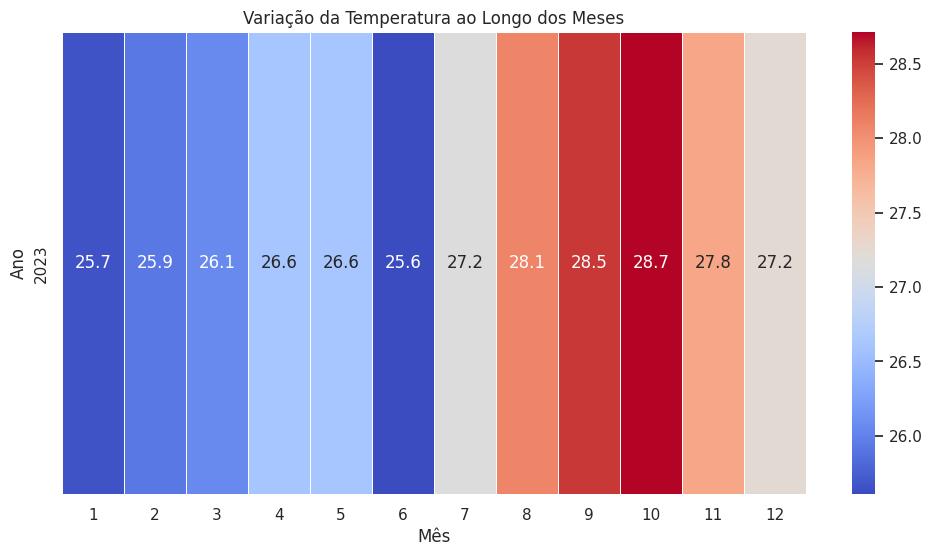

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar os dados
dados = pd.read_csv('/content/drive/MyDrive/generatedBy_react-csv (2).csv', sep=';', decimal=',')

# Converter data para datetime
dados['Data'] = pd.to_datetime(dados['Data'], format='%d/%m/%Y')

# Criar colunas de Ano e Mês
dados['Ano'] = dados['Data'].dt.year
dados['Mês'] = dados['Data'].dt.month

# Preencher valores ausentes com a média
dados.fillna(dados.mean(numeric_only=True), inplace=True)

# Selecionar a coluna de temperatura
dados['Temp. Ins. (C)'] = pd.to_numeric(dados['Temp. Ins. (C)'], errors='coerce')

# Criar Heatmap de variação de temperatura
heatmap_data = dados.groupby(['Ano', 'Mês'])['Temp. Ins. (C)'].mean().unstack()
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap="coolwarm", annot=True, fmt=".1f", linewidths=0.5)
plt.title("Variação da Temperatura ao Longo dos Meses")
plt.xlabel("Mês")
plt.ylabel("Ano")
plt.show()

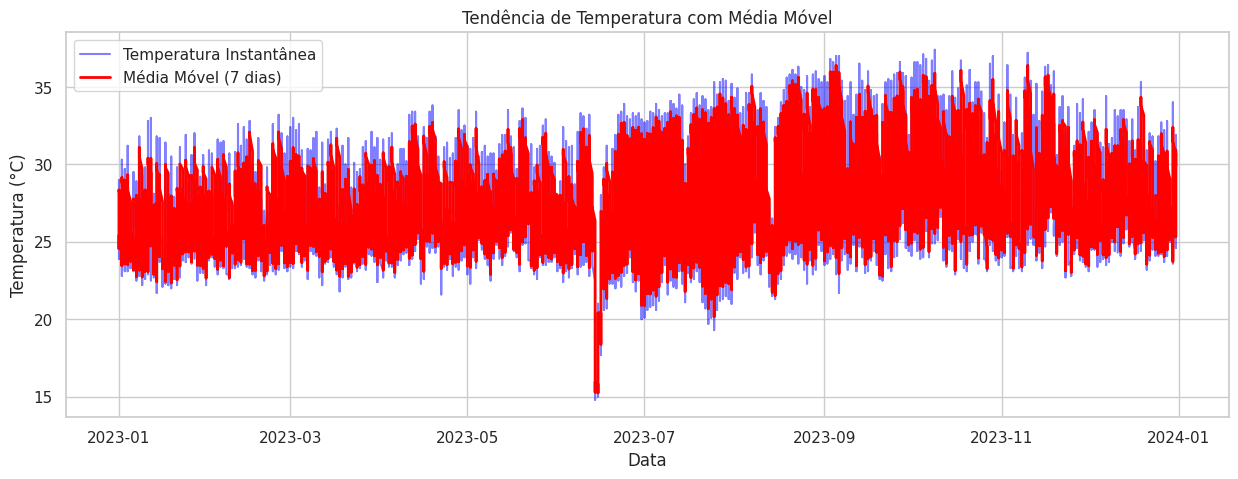

In [ ]:
coluna_temperatura="Temp. Ins. (C)"
# Aplicar uma média móvel de 7 dias para suavização dos dados
dados['Média Móvel (7 dias)'] = dados[coluna_temperatura].rolling(window=7).mean()

# Criar um gráfico de tendência com a média móvel
plt.figure(figsize=(15, 5))
plt.plot(dados['Data'], dados[coluna_temperatura], label='Temperatura Instantânea', color='blue', alpha=0.5)
plt.plot(dados['Data'], dados['Média Móvel (7 dias)'], label='Média Móvel (7 dias)', color='red', linewidth=2)

# Personalizar o gráfico
plt.xlabel('Data')
plt.ylabel('Temperatura (°C)')
plt.title('Tendência de Temperatura com Média Móvel')
plt.legend()
plt.grid(True)
plt.show()

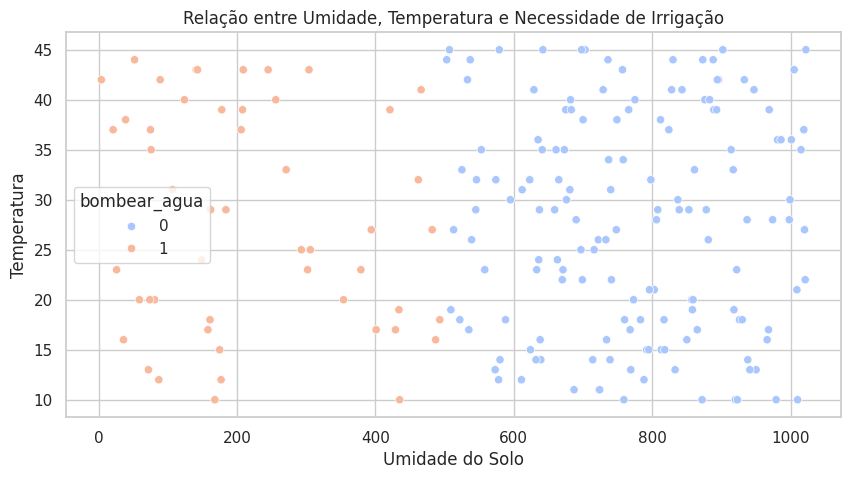

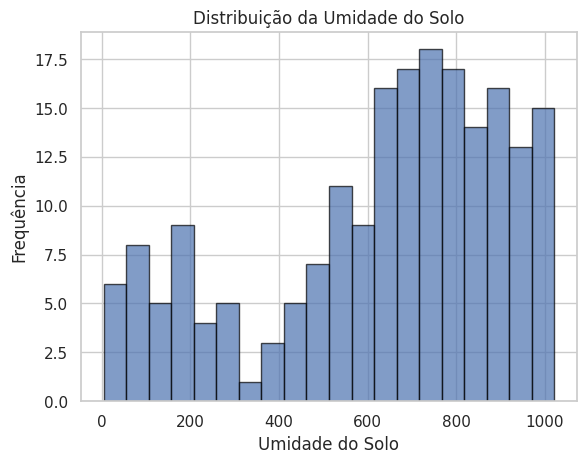

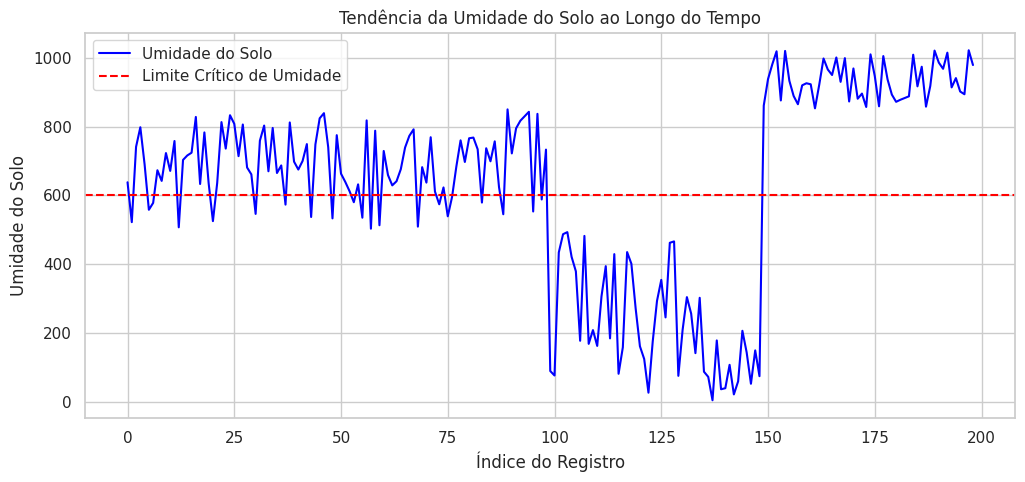

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar os dados do arquivo CSV
dados = pd.read_csv('/content/drive/MyDrive/data.csv')

# Verificar estatísticas básicas
dados.describe()

# Gráfico de dispersão: Umidade x Temperatura
plt.figure(figsize=(10, 5))
sns.scatterplot(x=dados['umidade'], y=dados['temperatura'], hue=dados['bombear_agua'], palette='coolwarm')
plt.xlabel("Umidade do Solo")
plt.ylabel("Temperatura")
plt.title("Relação entre Umidade, Temperatura e Necessidade de Irrigação")
plt.show()

# Histograma da Umidade do Solo
dados['umidade'].hist(bins=20, edgecolor='black', alpha=0.7)
plt.xlabel("Umidade do Solo")
plt.ylabel("Frequência")
plt.title("Distribuição da Umidade do Solo")
plt.show()

# Tendência da Umidade ao Longo do Tempo
plt.figure(figsize=(12, 5))
plt.plot(dados.index, dados['umidade'], label='Umidade do Solo', color='blue')
plt.axhline(y=600, color='red', linestyle='--', label='Limite Crítico de Umidade')
plt.xlabel("Índice do Registro")
plt.ylabel("Umidade do Solo")
plt.title("Tendência da Umidade do Solo ao Longo do Tempo")
plt.legend()
plt.grid(True)
plt.show()

   id_amostra tipo_solo   pH  materia_organica  teor_argila  teor_areia  \
0           1     Silte  6.7               2.7           51          44   
1           2  Argiloso  6.8               2.2           35          32   
2           3   Arenoso  6.0               4.3           44          49   
3           4  Argiloso  6.9               4.4           55          44   
4           5     Silte  6.2               2.3           29          66   

   teor_silte  nutrientes_npk  umidade cultura_plantada  produtividade  
0           5             186       18            Trigo             75  
1          33             103       13            Milho             50  
2           7             107       29             Soja             73  
3           1             188       19            Milho             33  
4           5             239       29             Soja             89  

Estatísticas básicas do dataset
        id_amostra         pH  materia_organica  teor_argila  teor_areia  \
co

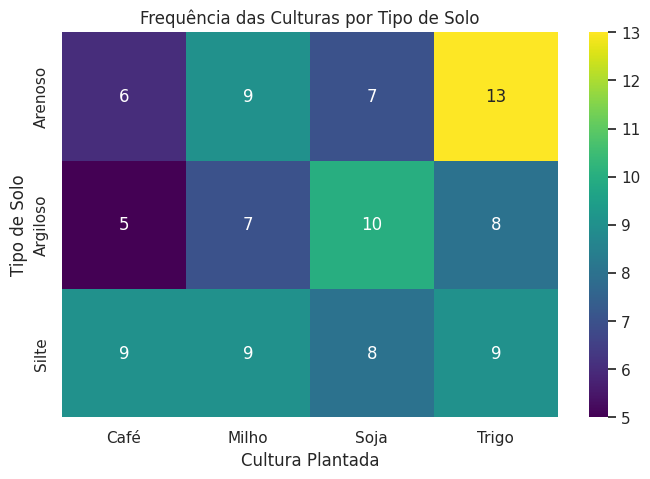

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar os dados do CSV
dados = pd.read_csv('/content/dados_agronomicos.csv')

# Exibir as primeiras linhas do dataset
print(dados.head())

# Estatísticas básicas do dataset
print("\nEstatísticas básicas do dataset\n", dados.describe())

# Melhor tipo de solo para cada cultura
melhores_solos = dados.groupby(['cultura_plantada', 'tipo_solo'])['produtividade'].mean().reset_index()
melhor_solo_por_cultura = melhores_solos.loc[melhores_solos.groupby('cultura_plantada')['produtividade'].idxmax()]
print("\nMelhor tipo de solo para cada cultura:")
print(melhor_solo_por_cultura)

# Criar heatmap
plt.figure(figsize=(8, 5))
tabela_heatmap = dados.pivot_table(index="tipo_solo", columns="cultura_plantada", aggfunc="size", fill_value=0)
sns.heatmap(tabela_heatmap, annot=True, cmap="viridis", fmt="d")
plt.xlabel("Cultura Plantada")
plt.ylabel("Tipo de Solo")
plt.title("Frequência das Culturas por Tipo de Solo")
plt.show()

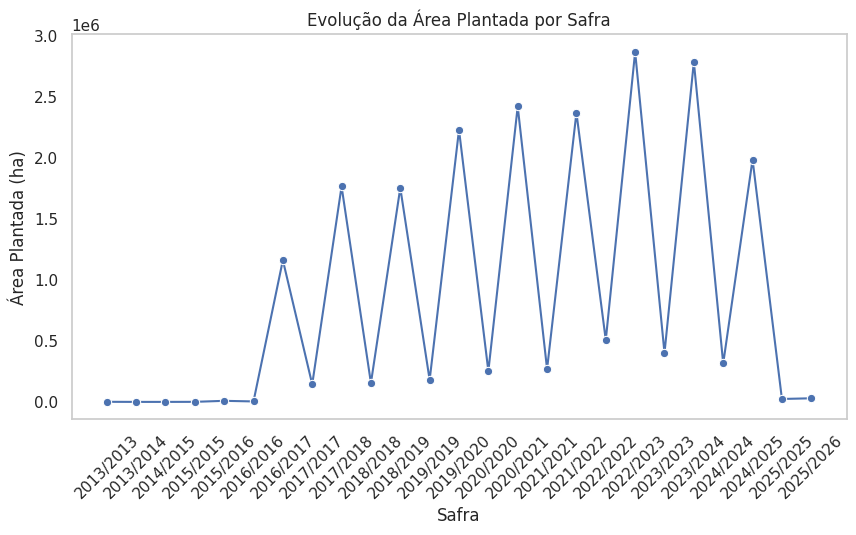

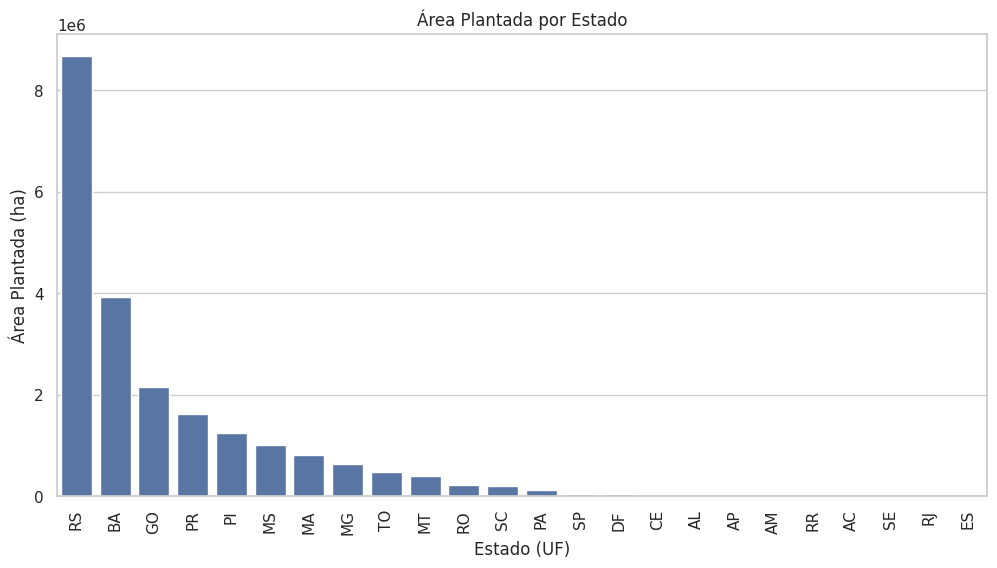

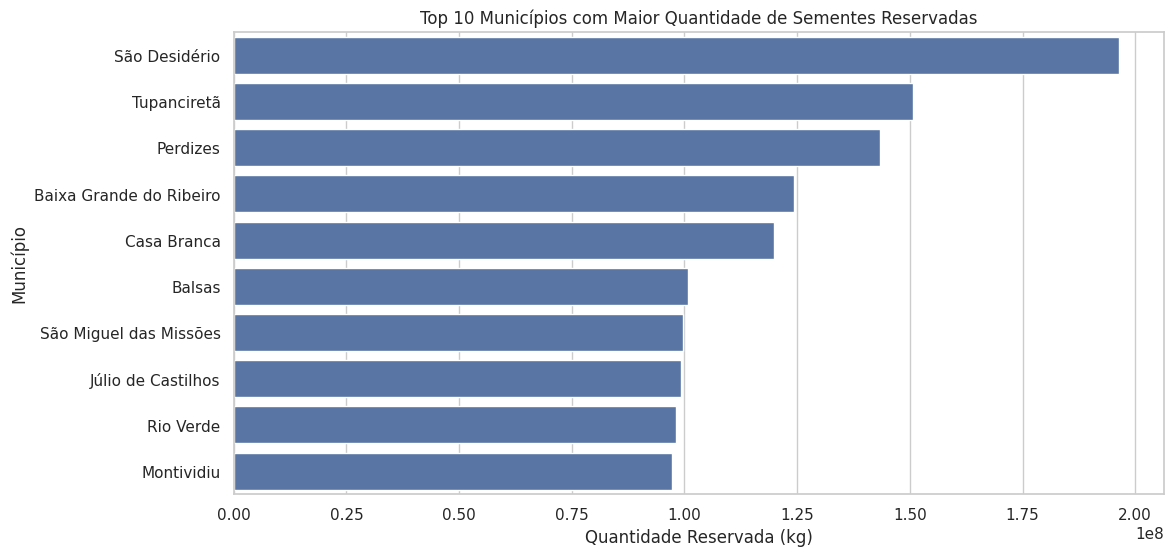

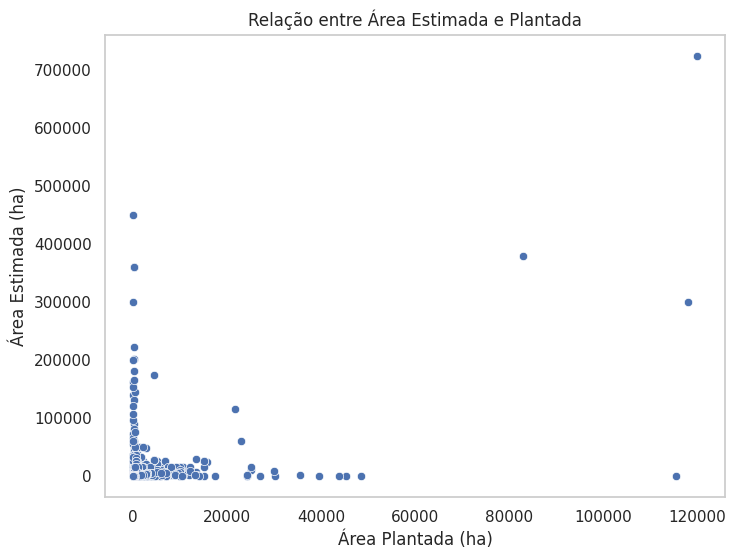

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar o dataset
file_path = '/content/sigefdeclaracaoareaproducao.csv'
df = pd.read_csv(file_path, encoding="utf8", delimiter=";")

# Converter coluna de data
if 'DATAPLANTIO' in df.columns:
    df['DATAPLANTIO'] = pd.to_datetime(df['DATAPLANTIO'], errors='coerce')

# Agrupar por período e somar a área plantada
area_por_safra = df.groupby('PERIODO')['AREAPLANTADA'].sum()

# Gráfico de evolução da área plantada ao longo das safras
plt.figure(figsize=(10,5))
sns.lineplot(x=area_por_safra.index, y=area_por_safra.values, marker='o')
plt.xticks(rotation=45)
plt.xlabel("Safra")
plt.ylabel("Área Plantada (ha)")
plt.title("Evolução da Área Plantada por Safra")
plt.grid()
plt.show()

# Distribuição da Área Plantada por Estado (UF)
plt.figure(figsize=(12,6))
area_por_estado = df.groupby('UF')['AREAPLANTADA'].sum().sort_values(ascending=False)
sns.barplot(x=area_por_estado.index, y=area_por_estado.values)
plt.xlabel("Estado (UF)")
plt.ylabel("Área Plantada (ha)")
plt.title("Área Plantada por Estado")
plt.xticks(rotation=90)
plt.show()

# Top 10 municípios com maior quantidade reservada de sementes
plt.figure(figsize=(12,6))
top_municipios = df.groupby('MUNICIPIO')['QUANTRESERVADA'].sum().sort_values(ascending=False).head(10)
sns.barplot(y=top_municipios.index, x=top_municipios.values)
plt.xlabel("Quantidade Reservada (kg)")
plt.ylabel("Município")
plt.title("Top 10 Municípios com Maior Quantidade de Sementes Reservadas")
plt.show()

# Comparação entre Área Estimada e Área Plantada
plt.figure(figsize=(8,6))
sns.scatterplot(x=df['AREAPLANTADA'], y=df['AREAESTIMADA'])
plt.xlabel("Área Plantada (ha)")
plt.ylabel("Área Estimada (ha)")
plt.title("Relação entre Área Estimada e Plantada")
plt.grid()
plt.show()

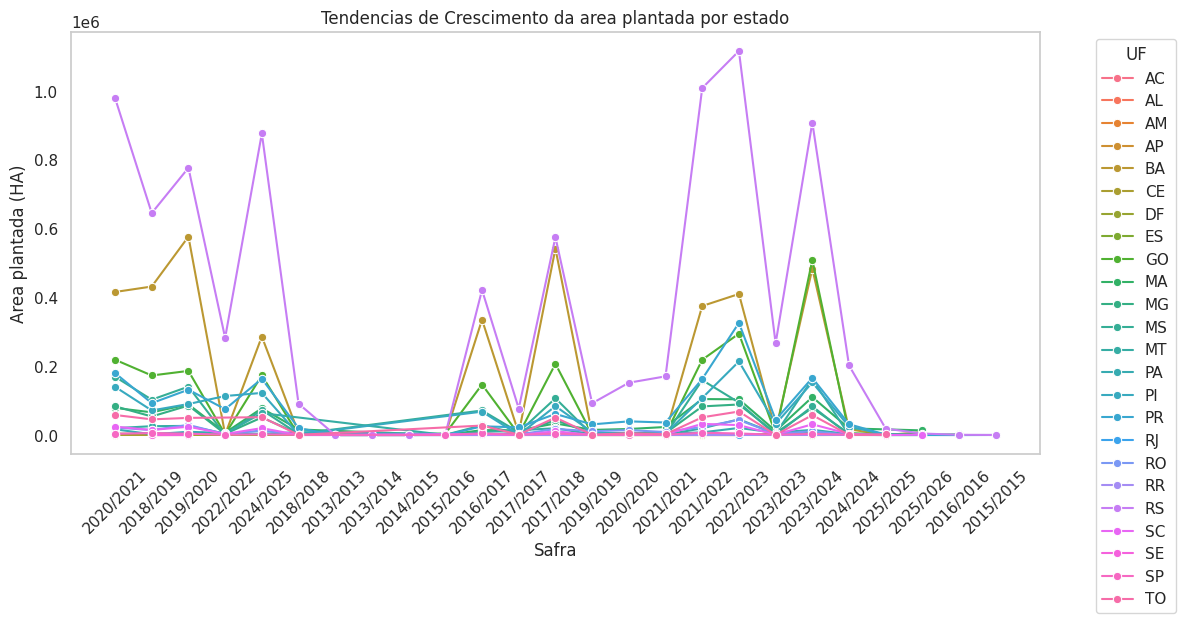

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
df_estado_safra=df.groupby(['UF','PERIODO'])['AREAPLANTADA'].sum().reset_index()
sns.lineplot(data=df_estado_safra, x='PERIODO', y='AREAPLANTADA',hue='UF',marker='o')
plt.title("Tendencias de Crescimento da area plantada por estado")
plt.xlabel("Safra")
plt.ylabel("Area plantada (HA)")
plt.xticks(rotation=45)
plt.legend(title="UF",bbox_to_anchor=(1.05,1),loc='upper left')
plt.grid()
plt.tight_layout()
plt.show()


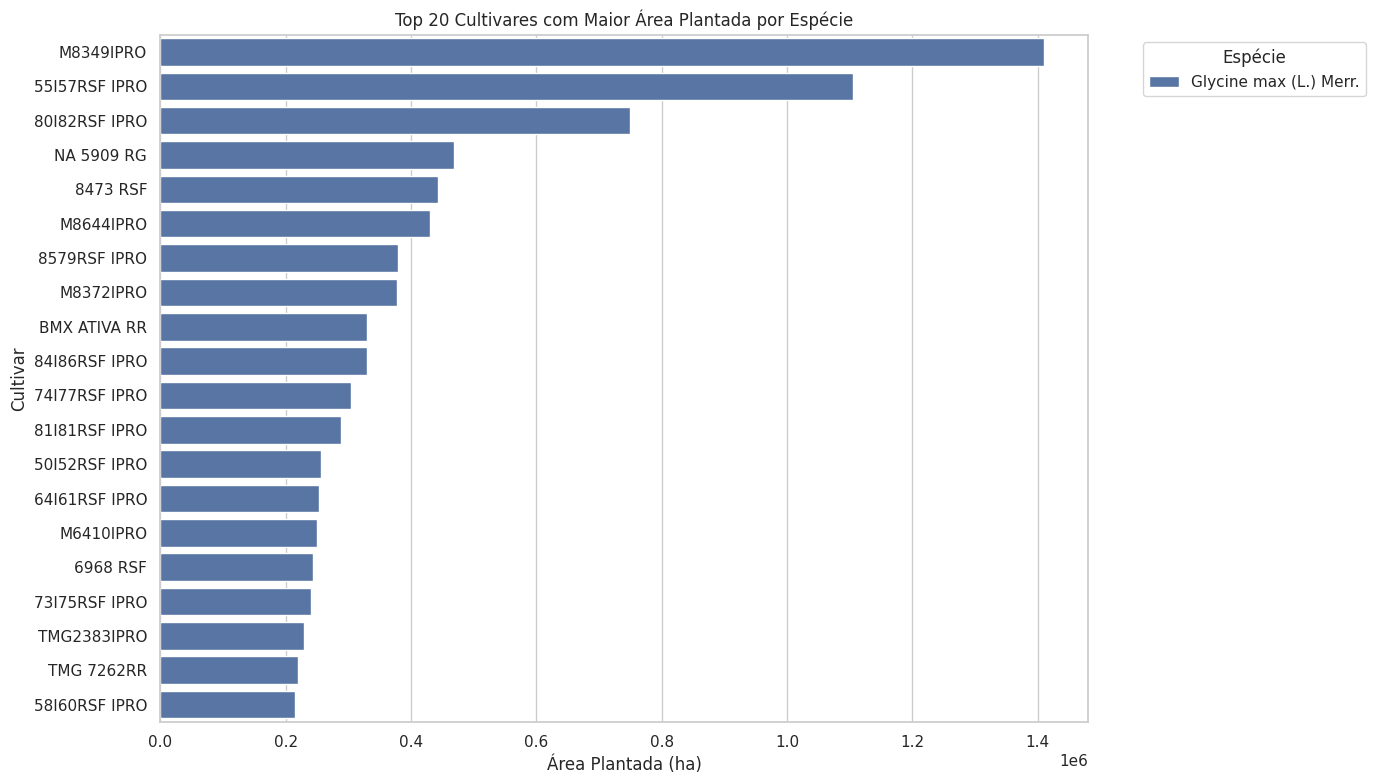

In [ ]:
# Análise por cultura e cultivar
plt.figure(figsize=(14,8))
cultivo = df.groupby(['ESPECIE', 'CULTIVAR'])['AREAPLANTADA'].sum().reset_index()
cultivo_top = cultivo.sort_values(by='AREAPLANTADA', ascending=False).head(20)
sns.barplot(data=cultivo_top, y='CULTIVAR', x='AREAPLANTADA', hue='ESPECIE')
plt.title("Top 20 Cultivares com Maior Área Plantada por Espécie")
plt.xlabel("Área Plantada (ha)")
plt.ylabel("Cultivar")
plt.legend(title="Espécie", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()